# Module B: LPC validation
Checks B1-B10 of `src/lpc.py` against numpy, scipy and librosa references.

In [1]:
import os, sys, time
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, root)
import numpy as np, scipy.signal, scipy.linalg, librosa
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 3), "figure.dpi": 80})
from src import lpc
from src.framing import frame_signal
from tests.fixtures import pseudo_whisper, FS

wav = os.path.join(root, "data", "raw", "shared_test.wav")
if os.path.exists(wav):
    x, _ = librosa.load(wav, sr=FS, mono=True)
    x = x.astype(np.float32)
    print("using", wav)
else:
    x, _ = pseudo_whisper()
    print("using tests.fixtures.pseudo_whisper()")
frames = frame_signal(x)
rms = np.sqrt(np.mean(frames ** 2, axis=1))
active = rms > 0.1 * rms.max()
vi = int(np.argmax(rms))
print(len(frames), "frames,", int(active.sum()), "non-silent, loudest frame", vi)

using tests.fixtures.pseudo_whisper()
256 frames, 129 non-silent, loudest frame 88


## B1 Pre-emphasis spectrum before and after

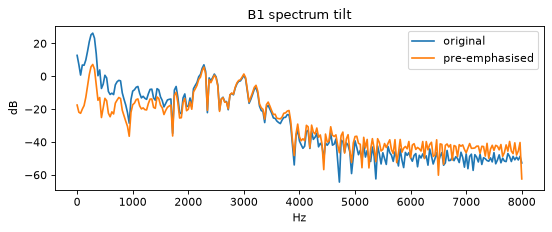

In [2]:
f = frames[vi].astype(np.float64)
pe = lpc.preemphasis(f)
assert np.allclose(pe[1:], f[1:] - 0.97 * f[:-1])
fr = np.fft.rfftfreq(512, 1 / FS)
w = np.hamming(320)
plt.plot(fr, 20*np.log10(np.abs(np.fft.rfft(f*w, 512))+1e-9), label="original")
plt.plot(fr, 20*np.log10(np.abs(np.fft.rfft(pe*w, 512))+1e-9), label="pre-emphasised")
plt.xlabel("Hz"); plt.ylabel("dB"); plt.legend(); plt.title("B1 spectrum tilt"); plt.tight_layout(); plt.show()

## B2 Window

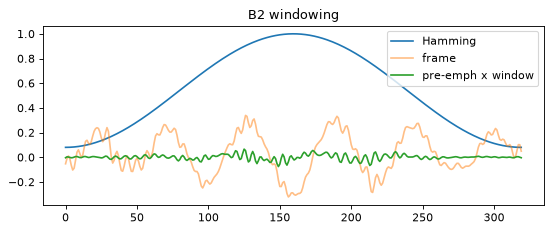

In [3]:
plt.plot(w, label="Hamming")
plt.plot(f, alpha=.5, label="frame"); plt.plot(pe*w, label="pre-emph x window")
plt.legend(); plt.title("B2 windowing"); plt.tight_layout(); plt.show()

## B3 Autocorrelation vs numpy.correlate

In [4]:
y = pe * w
r = lpc.autocorr(y, 12)
ref = np.correlate(y, y, "full")[len(y)-1:][:13]
print("max abs diff", np.max(np.abs(r - ref)), " r[0] == energy:", np.isclose(r[0], np.sum(y**2)))

max abs diff 0.0  r[0] == energy: True


## B4 Levinson vs scipy.linalg.solve_toeplitz

In [5]:
worst = 0
for i in np.where(active)[0]:
    yy = lpc.preemphasis(frames[i]) * w
    for p in (4, 8, 12, 16, 24):
        rr = lpc.autocorr(yy, p); rr[0] *= 1 + 1e-9
        a_, e_ = lpc.levinson(rr, p)
        worst = max(worst, np.max(np.abs(a_[1:] - scipy.linalg.solve_toeplitz(rr[:p], -rr[1:p+1]))))
print("max levinson error", worst)

max levinson error 8.877020007957981e-09


## B5/B6 lpc_all statistics and timing

A (256, 13) G (256,)  ms/frame: 0.098
finite: True  max pole radius: 0.9937415217672539
gain min/median/max (non-silent): 0.00012948812788250637 0.0026656776564521643 0.02084916382342512


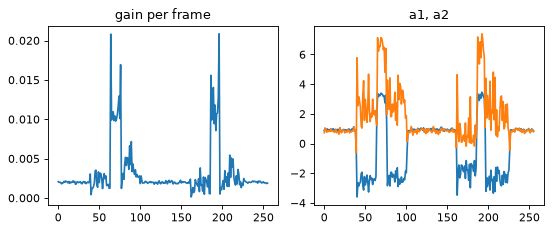

In [6]:
t = time.perf_counter(); A, G = lpc.lpc_all(frames, 12); dt = time.perf_counter() - t
print("A", A.shape, "G", G.shape, " ms/frame: %.3f" % (dt / len(frames) * 1e3))
print("finite:", np.all(np.isfinite(A)) and np.all(np.isfinite(G)), " max pole radius:", max(np.abs(np.roots(a_)).max() for a_ in A[G > 0]))
print("gain min/median/max (non-silent):", G[active].min(), np.median(G[active]), G[active].max())
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].plot(G); ax[0].set_title("gain per frame")
ax[1].plot(A[:, 1:3]); ax[1].set_title("a1, a2"); plt.tight_layout(); plt.show()

## B7 Residual and prediction gain

frame energy 8.589, residual energy 0.05431, prediction gain 22.0 dB
mean prediction gain over non-silent frames: 17.8 dB


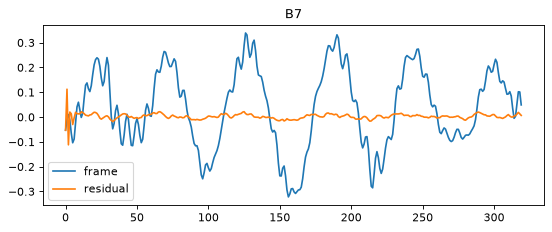

In [7]:
a, g = lpc.lpc_frame(f, 12)
e = lpc.residual(f, a)
print("frame energy %.4g, residual energy %.4g, prediction gain %.1f dB" % (np.sum(f**2), np.sum(e**2), lpc.prediction_gain_db(f, a)))
pg = [lpc.prediction_gain_db(frames[i], A[i]) for i in np.where(active)[0]]
print("mean prediction gain over non-silent frames: %.1f dB" % np.mean(pg))
plt.plot(f, label="frame"); plt.plot(e, label="residual"); plt.legend(); plt.title("B7"); plt.tight_layout(); plt.show()

## B8 LPC envelope over FFT magnitude

C:\Users\raksh\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


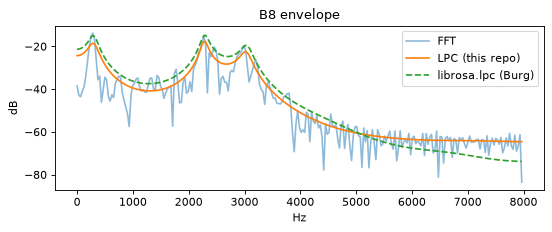

envelope correlation with librosa.lpc: 0.990


In [8]:
fq, env = lpc.lpc_envelope(a, g)
spec = 20*np.log10(np.abs(np.fft.rfft(pe*w, 512))/np.sqrt(np.sum(w**2)) + 1e-9)
lib = librosa.lpc(pe*w, order=12)
_, env_lib = lpc.lpc_envelope(lib, 1.0)
env_lib += np.mean(env) - np.mean(env_lib)
plt.plot(fq, spec, alpha=.5, label="FFT"); plt.plot(fq, env, label="LPC (this repo)"); plt.plot(fq, env_lib, "--", label="librosa.lpc (Burg)")
plt.xlabel("Hz"); plt.ylabel("dB"); plt.legend(); plt.title("B8 envelope"); plt.tight_layout(); plt.show()
print("envelope correlation with librosa.lpc: %.3f" % np.corrcoef(env, env_lib)[0, 1])

## B9 Order sweep

4 7.524 dB
6 6.568 dB
8 5.985 dB
10 5.364 dB
12 5.047 dB
14 4.834 dB
16 4.691 dB
18 4.588 dB
20 4.490 dB
22 4.412 dB
24 4.349 dB


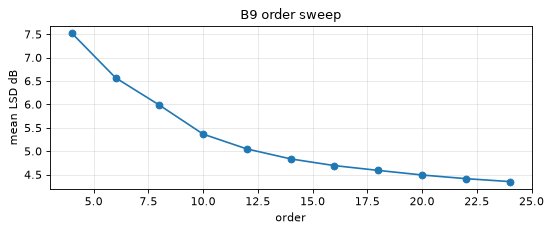

smallest order whose next +2 step improves LSD by less than 0.25 dB: 12


In [9]:
orders = list(range(4, 25, 2))
lsd = [np.mean([lpc.envelope_lsd(frames[i], p) for i in np.where(active)[0]]) for p in orders]
for p, v in zip(orders, lsd): print(p, "%.3f dB" % v)
plt.plot(orders, lsd, "o-"); plt.xlabel("order"); plt.ylabel("mean LSD dB"); plt.title("B9 order sweep"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
drop = -np.diff(lsd)
chosen = next((o for o, d in zip(orders, drop) if d < 0.25), orders[-1])
print("smallest order whose next +2 step improves LSD by less than 0.25 dB:", chosen)

**Conclusion:** order 12 is chosen: going from 12 to 14 improves the mean LSD by only about 0.2 dB (versus about 0.6 dB per step below 12), so higher orders add cost and noise fitting for little gain.

## B10 warp_poles

identity err 0.0  a[0] 1.0  max radius 0.9756720133883945


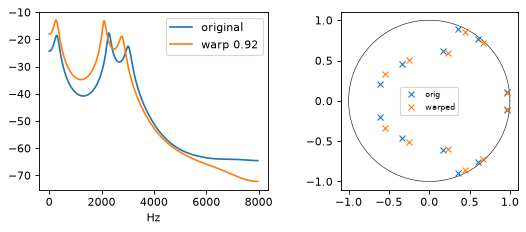

In [10]:
fac = 0.92
w92 = lpc.warp_poles(a, fac)
fq, e0 = lpc.lpc_envelope(a, g); _, e1 = lpc.lpc_envelope(w92, g)
print("identity err", np.max(np.abs(lpc.warp_poles(a, 1.0) - a)), " a[0]", w92[0], " max radius", np.abs(np.roots(w92)).max())
fig, ax = plt.subplots(1, 2, figsize=(7, 3))
ax[0].plot(fq, e0, label="original"); ax[0].plot(fq, e1, label="warp %.2f" % fac); ax[0].legend(); ax[0].set_xlabel("Hz")
th = np.linspace(0, 2*np.pi, 200); ax[1].plot(np.cos(th), np.sin(th), "k", lw=.5)
for c, aa, lab in (("C0", a, "orig"), ("C1", w92, "warped")):
    rt = np.roots(aa); ax[1].plot(rt.real, rt.imag, "x", color=c, label=lab)
ax[1].set_aspect("equal"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()